# 03 — Weather Data Quality Analysis

**RiskWeave | ERA5 daily weather | Sri Lanka**

Coverage: 23 December 2006–19 December 2025. Expected coverage: 25 districts × 6,937 days = 173,425 district-date rows.

This notebook analyses the consolidated master CSV without overwriting it, deleting outliers, or imputing values. Reports are saved separately under `outputs/weather_quality/`.

ERA5 is gridded reanalysis data, not direct measurements from district weather stations. The requested representative coordinates and API-returned ERA5 grid coordinates are distinct.


## 1. Import libraries

In [20]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


## 2. Configure paths and expected coverage

In [21]:
CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name.lower() == "notebooks" else CURRENT_DIR

MASTER_FILE = (
    PROJECT_DIR / "data" / "raw" / "weather_era5_2006_2025"
    / "weather_daily_era5_2006-12-23_to_2025-12-19.csv"
)
OUTPUT_DIR = PROJECT_DIR / "outputs" / "weather_quality"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = pd.Timestamp("2006-12-23")
END_DATE = pd.Timestamp("2025-12-19")
EXPECTED_DAYS_PER_DISTRICT = len(pd.date_range(START_DATE, END_DATE, freq="D"))
EXPECTED_DISTRICTS = 25
EXPECTED_TOTAL_ROWS = EXPECTED_DAYS_PER_DISTRICT * EXPECTED_DISTRICTS

WEATHER_VARIABLES = [
    "precipitation_sum", "rain_sum", "precipitation_hours",
    "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
    "relative_humidity_2m_mean", "relative_humidity_2m_max",
    "relative_humidity_2m_min", "dew_point_2m_mean",
    "wind_speed_10m_mean", "wind_speed_10m_max",
    "wind_direction_10m_dominant", "cloud_cover_mean",
    "shortwave_radiation_sum", "et0_fao_evapotranspiration"
]

print("Project:", PROJECT_DIR)
print("Master CSV:", MASTER_FILE)
print("File exists:", MASTER_FILE.exists())
print("Expected days/district:", EXPECTED_DAYS_PER_DISTRICT)
print("Expected total rows:", EXPECTED_TOTAL_ROWS)


Project: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Master CSV: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\raw\weather_era5_2006_2025\weather_daily_era5_2006-12-23_to_2025-12-19.csv
File exists: True
Expected days/district: 6937
Expected total rows: 173425


## 3. Load master weather dataset

In [22]:
if not MASTER_FILE.exists():
    raise FileNotFoundError(f"Master weather CSV not found: {MASTER_FILE}")

weather = pd.read_csv(MASTER_FILE)
print("Shape:", weather.shape)
display(weather.head())


Shape: (173425, 25)


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,wind_direction_10m_dominant,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,2006-12-23,6.800,6.800,22.000,25.300,27.100,24.200,89,94,81,23.200,14.900,18.100,13,99,13.740,2.800,7.125,81.685,7.000,81.750,48.000,era5,Asia/Colombo
1,Ampara,2006-12-24,3.400,3.400,19.000,25.600,27.300,23.800,87,94,81,23.200,17.000,22.100,16,97,11.360,2.600,7.125,81.685,7.000,81.750,48.000,era5,Asia/Colombo
2,Ampara,2006-12-25,3.800,3.800,11.000,25.200,26.400,24.000,83,87,79,22.100,17.000,20.800,1,100,6.420,2.080,7.125,81.685,7.000,81.750,48.000,era5,Asia/Colombo
3,Ampara,2006-12-26,1.300,1.300,8.000,25.500,27.400,23.600,81,89,73,21.900,16.700,22.600,9,98,12.890,3.190,7.125,81.685,7.000,81.750,48.000,era5,Asia/Colombo
4,Ampara,2006-12-27,0.000,0.000,0.000,25.400,28.000,23.500,77,84,67,21.000,14.600,21.300,9,93,14.110,3.480,7.125,81.685,7.000,81.750,48.000,era5,Asia/Colombo


## 4. Check required columns and data types

In [23]:
required = ["district", "date"] + WEATHER_VARIABLES
missing_columns = [c for c in required if c not in weather.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

weather["district"] = weather["district"].astype("string").str.strip()
weather["date"] = pd.to_datetime(weather["date"], errors="coerce")
for col in WEATHER_VARIABLES:
    weather[col] = pd.to_numeric(weather[col], errors="coerce")

display(weather.dtypes.astype(str).to_frame("data_type"))
print("Invalid dates:", weather["date"].isna().sum())


,data_type
district,string
date,datetime64[ns]
precipitation_sum,float64
rain_sum,float64
precipitation_hours,float64
temperature_2m_mean,float64
temperature_2m_max,float64
temperature_2m_min,float64
relative_humidity_2m_mean,int64
relative_humidity_2m_max,int64


Invalid dates: 0


## 5. Overall structure and completeness

In [24]:
overall = pd.DataFrame({
    "metric": [
        "Rows", "Districts", "Expected districts", "Weather variables",
        "First date", "Last date", "Duplicate district-date rows",
        "Invalid dates", "Missing district labels", "Expected total rows"
    ],
    "value": [
        len(weather), weather["district"].nunique(), EXPECTED_DISTRICTS,
        len(WEATHER_VARIABLES), weather["date"].min(), weather["date"].max(),
        weather.duplicated(["district", "date"]).sum(),
        weather["date"].isna().sum(), weather["district"].isna().sum(),
        EXPECTED_TOTAL_ROWS
    ]
})
display(overall)


,metric,value
0,Rows,173425
1,Districts,25
2,Expected districts,25
3,Weather variables,16
4,First date,2006-12-23 00:00:00
5,Last date,2025-12-19 00:00:00
6,Duplicate district-date rows,0
7,Invalid dates,0
8,Missing district labels,0
9,Expected total rows,173425


## 6. Missing values

In [25]:
missing_summary = weather[WEATHER_VARIABLES].isna().sum().to_frame("missing_count")
missing_summary["missing_percentage"] = missing_summary["missing_count"] / len(weather) * 100
display(missing_summary)
missing_summary.to_csv(OUTPUT_DIR / "weather_missing_values_summary.csv")


,missing_count,missing_percentage
precipitation_sum,0,0.000
rain_sum,0,0.000
precipitation_hours,0,0.000
temperature_2m_mean,0,0.000
temperature_2m_max,0,0.000
temperature_2m_min,0,0.000
relative_humidity_2m_mean,0,0.000
relative_humidity_2m_max,0,0.000
relative_humidity_2m_min,0,0.000
dew_point_2m_mean,0,0.000


## 7. Duplicate district-date records

In [26]:
duplicate_mask = weather.duplicated(["district", "date"], keep=False)
duplicates = weather.loc[duplicate_mask].sort_values(["district", "date"])
print("Duplicate rows:", len(duplicates))
display(duplicates.head(30))
duplicates.to_csv(OUTPUT_DIR / "weather_duplicate_district_date_records.csv", index=False)


Duplicate rows: 0


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,wind_direction_10m_dominant,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone


## 8. Date continuity and row counts by district

In [27]:
expected_dates = pd.date_range(START_DATE, END_DATE, freq="D")
continuity_rows = []

for district in sorted(weather["district"].dropna().unique()):
    part = weather.loc[weather["district"] == district]
    dates = pd.DatetimeIndex(part["date"].dropna().unique()).sort_values()
    missing_dates = expected_dates.difference(dates)
    unexpected_dates = dates.difference(expected_dates)
    continuity_rows.append({
        "district": district,
        "rows": len(part),
        "unique_dates": part["date"].nunique(),
        "missing_dates": len(missing_dates),
        "unexpected_dates": len(unexpected_dates),
        "duplicate_pairs": part.duplicated(["district", "date"]).sum(),
        "first_date": part["date"].min(),
        "last_date": part["date"].max(),
        "row_count_ok": len(part) == EXPECTED_DAYS_PER_DISTRICT,
        "date_coverage_ok": len(missing_dates) == 0 and len(unexpected_dates) == 0
    })

continuity = pd.DataFrame(continuity_rows)
display(continuity)
continuity.to_csv(OUTPUT_DIR / "weather_date_continuity_by_district.csv", index=False)


,district,rows,unique_dates,missing_dates,unexpected_dates,duplicate_pairs,first_date,last_date,row_count_ok,date_coverage_ok
0,Ampara,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
1,Anuradhapura,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
2,Badulla,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
3,Batticaloa,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
4,Colombo,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
5,Galle,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
6,Gampaha,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
7,Hambantota,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
8,Jaffna,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True
9,Kalutara,6937,6937,0,0,0,2006-12-23,2025-12-19,True,True


## 9. Descriptive statistics

In [28]:
descriptive = weather[WEATHER_VARIABLES].describe().T
descriptive["missing_count"] = weather[WEATHER_VARIABLES].isna().sum()
descriptive["unique_values"] = weather[WEATHER_VARIABLES].nunique()
display(descriptive)
descriptive.to_csv(OUTPUT_DIR / "weather_descriptive_statistics.csv")


,count,mean,std,min,25%,50%,75%,max,missing_count,unique_values
precipitation_sum,"173,425.000",5.369,10.407,0.000,0.100,1.600,6.400,310.400,0,1129
rain_sum,"173,425.000",5.369,10.407,0.000,0.100,1.600,6.400,310.400,0,1129
precipitation_hours,"173,425.000",7.182,7.048,0.000,1.000,5.000,12.000,24.000,0,25
temperature_2m_mean,"173,425.000",26.185,3.310,8.500,25.400,26.600,28.100,32.900,0,231
temperature_2m_max,"173,425.000",29.996,3.646,10.300,28.600,30.300,32.100,41.100,0,282
temperature_2m_min,"173,425.000",23.367,3.445,4.000,22.300,24.000,25.500,30.600,0,260
relative_humidity_2m_mean,"173,425.000",80.818,8.276,36.000,75.000,82.000,87.000,99.000,0,60
relative_humidity_2m_max,"173,425.000",92.204,6.043,50.000,89.000,94.000,97.000,100.000,0,43
relative_humidity_2m_min,"173,425.000",64.640,12.516,13.000,56.000,66.000,74.000,98.000,0,85
dew_point_2m_mean,"173,425.000",22.362,3.013,-2.000,21.600,23.300,24.200,27.700,0,252


## 10. Variable units reference

| Variable | Unit |
|---|---|
| `precipitation_sum`, `rain_sum` | mm |
| `precipitation_hours` | hours |
| `temperature_2m_mean`, `temperature_2m_max`, `temperature_2m_min`, `dew_point_2m_mean` | °C |
| `relative_humidity_2m_mean`, `relative_humidity_2m_max`, `relative_humidity_2m_min`, `cloud_cover_mean` | % |
| `wind_speed_10m_mean`, `wind_speed_10m_max` | km/h |
| `wind_direction_10m_dominant` | degrees |
| `shortwave_radiation_sum` | MJ/m² |
| `et0_fao_evapotranspiration` | mm |

These are the requested Open-Meteo daily variable units. Confirm them against the API response metadata retained in your district JSON files.


## 11. Broad physical-range screening

In [29]:
# Broad screening bounds only. These are not automatic deletion rules.
# A flagged value should be investigated; a climate extreme may be genuine.
limits = {
    "precipitation_sum": (0, None), "rain_sum": (0, None),
    "precipitation_hours": (0, 24),
    "temperature_2m_mean": (-90, 65), "temperature_2m_max": (-90, 65),
    "temperature_2m_min": (-90, 65), "dew_point_2m_mean": (-100, 65),
    "relative_humidity_2m_mean": (0, 100),
    "relative_humidity_2m_max": (0, 100),
    "relative_humidity_2m_min": (0, 100),
    "wind_speed_10m_mean": (0, None), "wind_speed_10m_max": (0, None),
    "wind_direction_10m_dominant": (0, 360),
    "cloud_cover_mean": (0, 100),
    "shortwave_radiation_sum": (0, None),
    "et0_fao_evapotranspiration": (0, None)
}
range_rows = []
for variable, (lower, upper) in limits.items():
    s = weather[variable]
    below = s < lower if lower is not None else pd.Series(False, index=s.index)
    above = s > upper if upper is not None else pd.Series(False, index=s.index)
    range_rows.append({
        "variable": variable, "lower_limit": lower, "upper_limit": upper,
        "below_lower": int(below.sum()), "above_upper": int(above.sum()),
        "total_flagged": int((below | above).sum())
    })
range_screening = pd.DataFrame(range_rows)
display(range_screening)
range_screening.to_csv(OUTPUT_DIR / "weather_physical_range_screening.csv", index=False)


,variable,lower_limit,upper_limit,below_lower,above_upper,total_flagged
0,precipitation_sum,0,NaN,0,0,0
1,rain_sum,0,NaN,0,0,0
2,precipitation_hours,0,24.000,0,0,0
3,temperature_2m_mean,-90,65.000,0,0,0
4,temperature_2m_max,-90,65.000,0,0,0
5,temperature_2m_min,-90,65.000,0,0,0
6,dew_point_2m_mean,-100,65.000,0,0,0
7,relative_humidity_2m_mean,0,100.000,0,0,0
8,relative_humidity_2m_max,0,100.000,0,0,0
9,relative_humidity_2m_min,0,100.000,0,0,0


## 12. Logical consistency checks

In [30]:
logical_checks = {
    "temperature_min_above_mean": weather["temperature_2m_min"] > weather["temperature_2m_mean"],
    "temperature_mean_above_max": weather["temperature_2m_mean"] > weather["temperature_2m_max"],
    "temperature_min_above_max": weather["temperature_2m_min"] > weather["temperature_2m_max"],
    "humidity_min_above_mean": weather["relative_humidity_2m_min"] > weather["relative_humidity_2m_mean"],
    "humidity_mean_above_max": weather["relative_humidity_2m_mean"] > weather["relative_humidity_2m_max"],
    "humidity_min_above_max": weather["relative_humidity_2m_min"] > weather["relative_humidity_2m_max"],
    "wind_mean_above_max": weather["wind_speed_10m_mean"] > weather["wind_speed_10m_max"],
    "rain_above_precipitation": weather["rain_sum"] > weather["precipitation_sum"]
}
logical_summary = pd.DataFrame([
    {"check": name, "flagged_rows": int(mask.fillna(False).sum())}
    for name, mask in logical_checks.items()
])
display(logical_summary)
logical_summary.to_csv(OUTPUT_DIR / "weather_logical_consistency_checks.csv", index=False)


,check,flagged_rows
0,temperature_min_above_mean,0
1,temperature_mean_above_max,0
2,temperature_min_above_max,0
3,humidity_min_above_mean,0
4,humidity_mean_above_max,0
5,humidity_min_above_max,0
6,wind_mean_above_max,0
7,rain_above_precipitation,0


## 13. Statistical outlier screening (IQR)

In [31]:
# IQR flags are exploratory only. Do not remove climate extremes automatically.
iqr_rows, flagged_parts = [], []
for variable in WEATHER_VARIABLES:
    q1 = weather[variable].quantile(0.25)
    q3 = weather[variable].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (weather[variable] < low) | (weather[variable] > high)
    iqr_rows.append({
        "variable": variable, "q1": q1, "q3": q3, "iqr": iqr,
        "lower_bound": low, "upper_bound": high,
        "flagged_count": int(mask.sum()),
        "flagged_percentage": float(mask.mean() * 100)
    })
    if mask.any():
        p = weather.loc[mask, ["district", "date", variable]].copy()
        p = p.rename(columns={variable: "value"})
        p["variable"] = variable
        flagged_parts.append(p)

iqr_summary = pd.DataFrame(iqr_rows)
display(iqr_summary)
iqr_summary.to_csv(OUTPUT_DIR / "weather_iqr_outlier_summary.csv", index=False)

iqr_records = (
    pd.concat(flagged_parts, ignore_index=True)
    if flagged_parts else pd.DataFrame(columns=["district", "date", "value", "variable"])
)
iqr_records.to_csv(OUTPUT_DIR / "weather_iqr_flagged_records.csv", index=False)
print("IQR flagged observations:", len(iqr_records))


,variable,q1,q3,iqr,lower_bound,upper_bound,flagged_count,flagged_percentage
0,precipitation_sum,0.100,6.400,6.300,-9.350,15.850,15617,9.005
1,rain_sum,0.100,6.400,6.300,-9.350,15.850,15617,9.005
2,precipitation_hours,1.000,12.000,11.000,-15.500,28.500,0,0.000
3,temperature_2m_mean,25.400,28.100,2.700,21.350,32.150,10516,6.064
4,temperature_2m_max,28.600,32.100,3.500,23.350,37.350,8641,4.983
5,temperature_2m_min,22.300,25.500,3.200,17.500,30.300,8909,5.137
6,relative_humidity_2m_mean,75.000,87.000,12.000,57.000,105.000,916,0.528
7,relative_humidity_2m_max,89.000,97.000,8.000,77.000,109.000,3057,1.763
8,relative_humidity_2m_min,56.000,74.000,18.000,29.000,101.000,316,0.182
9,dew_point_2m_mean,21.600,24.200,2.600,17.700,28.100,10173,5.866


IQR flagged observations: 84217


## 14. District coordinate and ERA5 grid metadata

In [32]:
metadata_cols = [
    c for c in [
        "requested_latitude", "requested_longitude",
        "era5_grid_latitude", "era5_grid_longitude",
        "era5_grid_elevation_m", "model", "timezone"
    ] if c in weather.columns
]

if metadata_cols:
    district_metadata = weather.groupby("district")[metadata_cols].first().reset_index()
    metadata_variation = weather.groupby("district")[metadata_cols].nunique(dropna=False)
    display(district_metadata)
    print("Within-district metadata variation:")
    display(metadata_variation)
    district_metadata.to_csv(OUTPUT_DIR / "weather_district_grid_metadata.csv", index=False)
    if {"era5_grid_latitude", "era5_grid_longitude"}.issubset(district_metadata.columns):
        print("Distinct ERA5 grid coordinate pairs:",
              district_metadata[["era5_grid_latitude", "era5_grid_longitude"]].drop_duplicates().shape[0])
else:
    print("Coordinate metadata columns are absent. Check collection output schema.")


,district,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,7.125,81.685,7.000,81.750,48.000,era5,Asia/Colombo
1,Anuradhapura,8.369,80.440,8.250,80.500,89.000,era5,Asia/Colombo
2,Badulla,7.082,81.089,7.000,81.000,745.000,era5,Asia/Colombo
3,Batticaloa,7.834,81.410,7.750,81.500,20.000,era5,Asia/Colombo
4,Colombo,6.849,80.029,6.750,80.000,30.000,era5,Asia/Colombo
5,Galle,6.204,80.231,6.250,80.250,16.000,era5,Asia/Colombo
6,Gampaha,7.119,80.021,7.000,80.000,12.000,era5,Asia/Colombo
7,Hambantota,6.276,81.178,6.250,81.250,50.000,era5,Asia/Colombo
8,Jaffna,9.643,79.909,9.750,80.000,5.000,era5,Asia/Colombo
9,Kalutara,6.576,80.135,6.500,80.250,150.000,era5,Asia/Colombo


Within-district metadata variation:


,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
district,,,,,,,
Ampara,1,1,1,1,1,1,1
Anuradhapura,1,1,1,1,1,1,1
Badulla,1,1,1,1,1,1,1
Batticaloa,1,1,1,1,1,1,1
Colombo,1,1,1,1,1,1,1
Galle,1,1,1,1,1,1,1
Gampaha,1,1,1,1,1,1,1
Hambantota,1,1,1,1,1,1,1
Jaffna,1,1,1,1,1,1,1


Distinct ERA5 grid coordinate pairs: 25


## 15. Plot distributions of selected variables

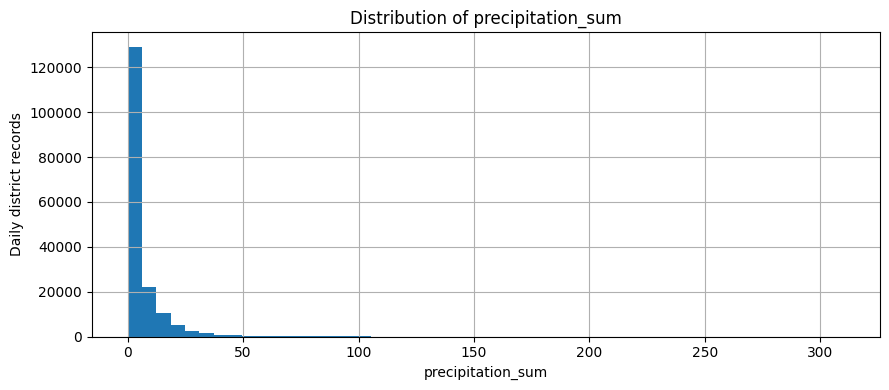

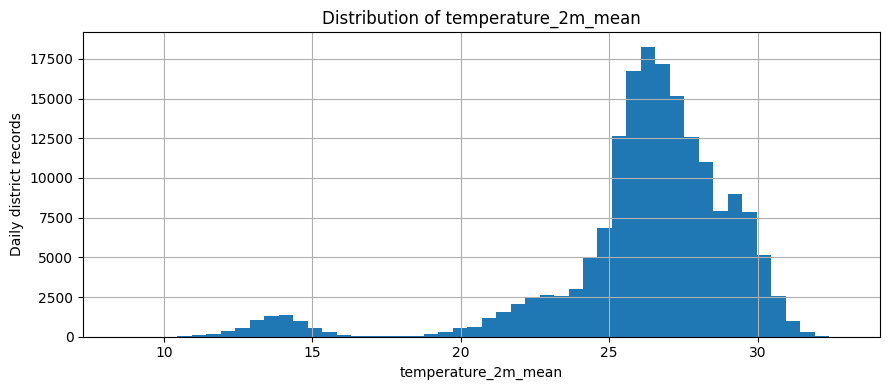

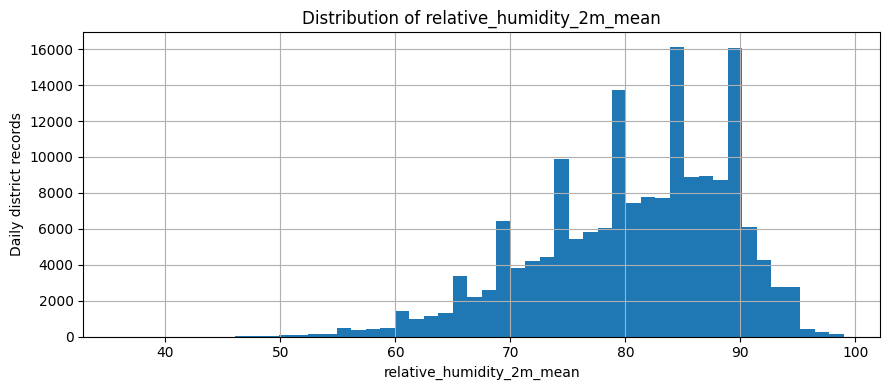

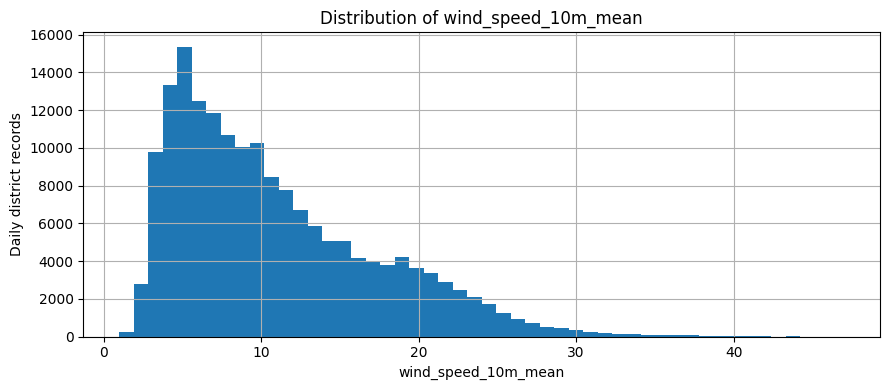

In [33]:
for variable in [
    "precipitation_sum", "temperature_2m_mean",
    "relative_humidity_2m_mean", "wind_speed_10m_mean"
]:
    plt.figure(figsize=(9, 4))
    weather[variable].dropna().hist(bins=50)
    plt.title(f"Distribution of {variable}")
    plt.xlabel(variable)
    plt.ylabel("Daily district records")
    plt.tight_layout()
    plt.show()


## 16. Plot time series for one district

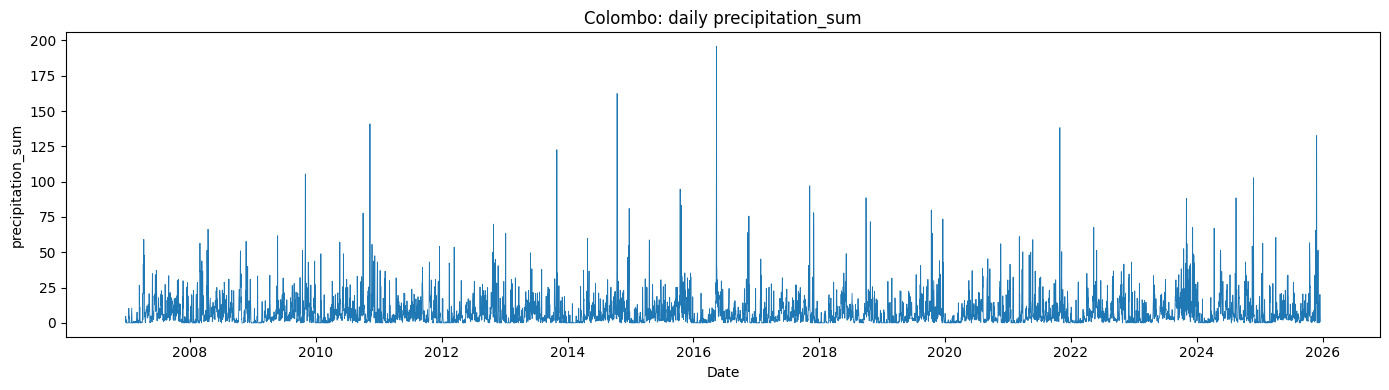

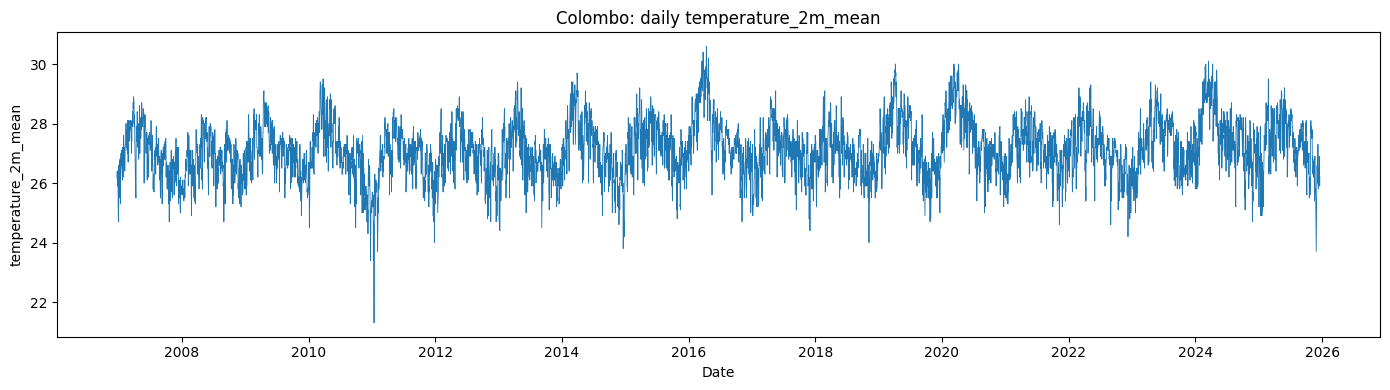

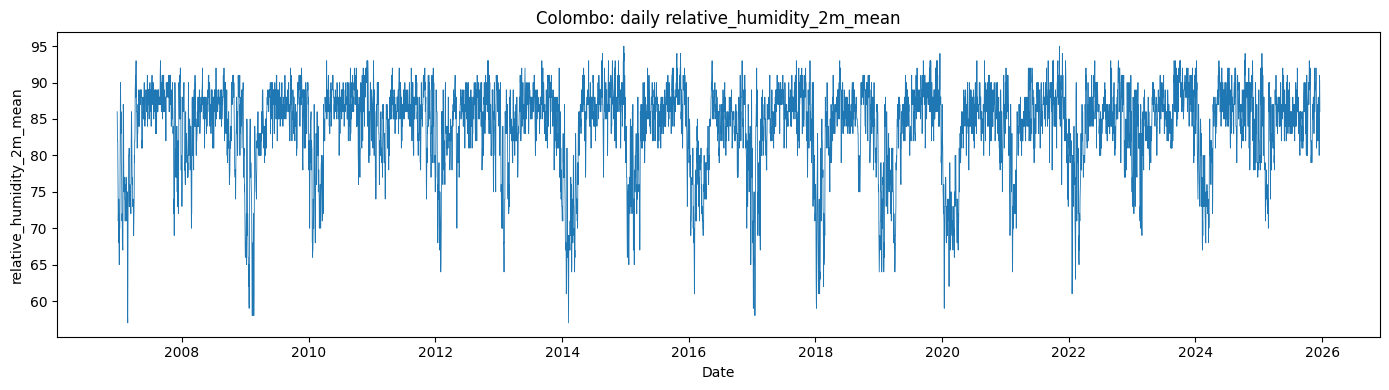

In [34]:
selected_district = "Colombo"  # Change to an exact district value if required
if selected_district not in weather["district"].dropna().unique():
    raise ValueError(f"{selected_district} not found in the dataset.")

district_weather = weather.loc[weather["district"] == selected_district].sort_values("date")
for variable in ["precipitation_sum", "temperature_2m_mean", "relative_humidity_2m_mean"]:
    plt.figure(figsize=(14, 4))
    plt.plot(district_weather["date"], district_weather[variable], linewidth=0.6)
    plt.title(f"{selected_district}: daily {variable}")
    plt.xlabel("Date")
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()


## 17. Compare district date sequences

In [35]:
date_sequences = {}
for district in sorted(weather["district"].dropna().unique()):
    date_sequences[district] = (
        weather.loc[weather["district"] == district, "date"]
        .dropna().sort_values().reset_index(drop=True)
    )

reference_district = next(iter(date_sequences))
reference_dates = date_sequences[reference_district]
sequence_report = pd.DataFrame([
    {
        "district": district,
        "same_sequence_as_reference": dates.equals(reference_dates),
        "reference_district": reference_district,
        "date_count": len(dates)
    }
    for district, dates in date_sequences.items()
])
display(sequence_report)
sequence_report.to_csv(OUTPUT_DIR / "weather_date_sequence_comparison.csv", index=False)


,district,same_sequence_as_reference,reference_district,date_count
0,Ampara,True,Ampara,6937
1,Anuradhapura,True,Ampara,6937
2,Badulla,True,Ampara,6937
3,Batticaloa,True,Ampara,6937
4,Colombo,True,Ampara,6937
5,Galle,True,Ampara,6937
6,Gampaha,True,Ampara,6937
7,Hambantota,True,Ampara,6937
8,Jaffna,True,Ampara,6937
9,Kalutara,True,Ampara,6937


## 18. Save consolidated quality-control summary

In [36]:
summary = {
    "master_file": str(MASTER_FILE),
    "rows": int(len(weather)),
    "districts": int(weather["district"].nunique()),
    "weather_variables": int(len(WEATHER_VARIABLES)),
    "expected_start": str(START_DATE.date()),
    "expected_end": str(END_DATE.date()),
    "observed_start": str(weather["date"].min().date()) if weather["date"].notna().any() else None,
    "observed_end": str(weather["date"].max().date()) if weather["date"].notna().any() else None,
    "expected_rows": int(EXPECTED_TOTAL_ROWS),
    "duplicate_district_date_rows": int(weather.duplicated(["district", "date"]).sum()),
    "invalid_dates": int(weather["date"].isna().sum()),
    "missing_weather_values": int(weather[WEATHER_VARIABLES].isna().sum().sum()),
    "districts_with_expected_rows": int((continuity["rows"] == EXPECTED_DAYS_PER_DISTRICT).sum()),
    "districts_with_complete_date_coverage": int(continuity["date_coverage_ok"].sum()),
    "note": "Outlier and range flags require review. No records were automatically deleted or imputed."
}
display(pd.DataFrame([{"metric": k, "value": v} for k, v in summary.items()]))

with open(OUTPUT_DIR / "weather_quality_control_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("Reports saved in:", OUTPUT_DIR)


,metric,value
0,master_file,c:\Users\Nethmi\Documents\GitHub\RiskWeave\dat...
1,rows,173425
2,districts,25
3,weather_variables,16
4,expected_start,2006-12-23
5,expected_end,2025-12-19
6,observed_start,2006-12-23
7,observed_end,2025-12-19
8,expected_rows,173425
9,duplicate_district_date_rows,0


Reports saved in: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_quality


In [37]:
# Check whether precipitation_sum and rain_sum are identical

same_values = (
    weather["precipitation_sum"]
    == weather["rain_sum"]
)

print("Identical records:", same_values.sum())
print("Different records:", (~same_values).sum())
print(
    "Correlation:",
    weather["precipitation_sum"].corr(
        weather["rain_sum"]
    )
)

Identical records: 173425
Different records: 0
Correlation: 0.9999999999999998


In [38]:
grid = weather[
    ["district", "era5_grid_latitude", "era5_grid_longitude"]
].drop_duplicates()

print("Districts:", grid["district"].nunique())

print(
    "Distinct ERA5 grid cells:",
    grid[
        ["era5_grid_latitude", "era5_grid_longitude"]
    ].drop_duplicates().shape[0]
)

display(grid)

Districts: 25
Distinct ERA5 grid cells: 25


,district,era5_grid_latitude,era5_grid_longitude
0,Ampara,7.000,81.750
6937,Anuradhapura,8.250,80.500
13874,Badulla,7.000,81.000
20811,Batticaloa,7.750,81.500
27748,Colombo,6.750,80.000
34685,Galle,6.250,80.250
41622,Gampaha,7.000,80.000
48559,Hambantota,6.250,81.250
55496,Jaffna,9.750,80.000
62433,Kalutara,6.500,80.250
